In [36]:
import os
import warnings
import joblib

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import rasterio
from rasterio.mask import mask
from rasterio.features import geometry_mask
from rasterio.plot import show

from sklearn.ensemble import RandomForestClassifier
from coral import coral_fit,coral_apply

warnings.filterwarnings("ignore")

np.random.seed(42)

In [37]:
# -----------------------------
# KRISHNA DATA
# -----------------------------

KRISHNA_IMAGE = r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2024.tif"

KRISHNA_AOI = r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\krishna_east_div\krishna_east_div.shp"

KRISHNA_GT = r"C:\Users\snvra\NISAR_Data_project\Data\krishna_gt\train_2024.shp"

# -----------------------------
# PICHAVARAM DATA
# -----------------------------

PICH_IMAGE = r"C:\Users\snvra\NISAR_Data_project\Data\Pich_SatEmb_2025\Pichavaram_Mosaic.tif"

PICH_AOI = r"C:\Users\snvra\NISAR_Data_project\Data\pich_mang\pich_mang_mask.shp"

PICH_GT = r"C:\Users\snvra\NISAR_Data_project\Data\pichhavaram_gt\pich_gt.shp"

# -----------------------------
# OUTPUT
# -----------------------------

OUTPUT_FOLDER = r"C:\Users\snvra\NISAR_Data_project\classifier models"

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

In [38]:
# Krishna GT
krishna_gt = gpd.read_file(KRISHNA_GT)

# Krishna AOI
krishna_aoi=gpd.read_file(KRISHNA_AOI)

# pichavaram AOI
pich_aoi = gpd.read_file(PICH_AOI)

# Krishna raster
krishna_src = rasterio.open(KRISHNA_IMAGE)

# pichavaram raster
pich_src = rasterio.open(PICH_IMAGE)

In [39]:
# Crop Krishna raster to AOI
krishna_clip, krishna_transform = mask(
    krishna_src,
    krishna_aoi.geometry,
    crop=True,
    filled=True,
    nodata=np.nan
)

# Convert to (rows, cols, bands)
krishna_clip = np.moveaxis(
    krishna_clip,
    0,
    -1
)

print("Krishna AOI Shape :", krishna_clip.shape)

Krishna AOI Shape : (2069, 1919, 64)


In [40]:
# Valid pixels

krishna_valid = np.all(
    np.isfinite(krishna_clip),
    axis=2
)

# Reference feature matrix

X_reference = krishna_clip[krishna_valid]

print("Reference Features :", X_reference.shape)

print()

print("Any NaN :", np.isnan(X_reference).any())
print("Any Inf :", np.isinf(X_reference).any())

print()

print("Minimum :", X_reference.min())
print("Maximum :", X_reference.max())

Reference Features : (1846701, 64)

Any NaN : False
Any Inf : False

Minimum : -0.4982698961937717
Maximum : 0.4982698961937717


In [41]:
pich_clip, pich_transform = mask(
    pich_src,
    pich_aoi.geometry,
    crop=True,
    filled=True,
    nodata=np.nan
)

pich_clip = np.moveaxis(
    pich_clip,
    0,
    -1
)

rows, cols, bands = pich_clip.shape

valid_mask = np.all(
    np.isfinite(pich_clip),
    axis=2
)

X_target = pich_clip[valid_mask]

print(X_target.shape)

(81383, 64)


In [42]:
print("Raster CRS :", pich_src.crs)
print("AOI CRS    :", pich_aoi.crs)

Raster CRS : EPSG:4326
AOI CRS    : EPSG:4326


In [43]:
params = coral_fit(
    X_target,
    X_reference
)

aligned_pixels = coral_apply(
    X_target,
    params
)

print(aligned_pixels.shape)

(81383, 64)


In [44]:
# Covariance matrices
cov_source = np.cov(X_reference, rowvar=False)
cov_target = np.cov(X_target, rowvar=False)
cov_aligned = np.cov(aligned_pixels, rowvar=False)

# Frobenius norm of covariance difference
before = np.linalg.norm(cov_source - cov_target, ord='fro')
after = np.linalg.norm(cov_source - cov_aligned, ord='fro')

print("=" * 60)
print(f"Covariance Difference Before CORAL : {before:.6f}")
print(f"Covariance Difference After CORAL  : {after:.6f}")
print(f"Absolute Reduction                 : {before - after:.6f}")
print(f"Percentage Reduction               : {(before - after) / before * 100:.2f}%")
print("=" * 60)

Covariance Difference Before CORAL : 0.206367
Covariance Difference After CORAL  : 0.001653
Absolute Reduction                 : 0.204715
Percentage Reduction               : 99.20%


In [45]:
import numpy as np
from rasterio.features import geometry_mask

def extract_binary_training(raster, gt, transform, target_species):
   
    X_train = []
    y_train = []

    rows, cols, bands = raster.shape

    for _, feature in gt.iterrows():

        mask = geometry_mask(
            [feature.geometry],
            transform=transform,
            invert=True,
            out_shape=(rows, cols)
        )

        r, c = np.where(mask)

        for rr, cc in zip(r, c):

            pixel = raster[rr, cc, :]   # (bands,)

            if np.isnan(pixel).any():
                continue

            X_train.append(pixel)

            if feature["label"] == target_species:
                y_train.append(1)
            else:
                y_train.append(0)

    return np.asarray(X_train), np.asarray(y_train)

In [46]:
species_list = [
    "A_marina_dense",
    "A_marina_sparse_rej",
    "Rhizophora_sp",
]

species_short = {
    "A_marina_dense": "Dense",
    "A_marina_sparse_rej":"Sparse",
    "Rhizophora_sp": "Rhizophora",
}

MODEL_FOLDER = os.path.join(OUTPUT_FOLDER, "Models")
MAP_FOLDER = os.path.join(OUTPUT_FOLDER, "Probability_Maps")

os.makedirs(MODEL_FOLDER, exist_ok=True)
os.makedirs(MAP_FOLDER, exist_ok=True)

for species in species_list:

    print("="*70)
    print("Training :", species)

    # ---------------------------------------------------
    # Extract Binary Training Data
    # ---------------------------------------------------

    X_train, y_train = extract_binary_training(
        raster=krishna_clip,
        gt=krishna_gt,
        transform=krishna_transform,
        target_species=species
    )

    print("Training Samples")
    print(np.unique(y_train, return_counts=True))

    # ---------------------------------------------------
    # Train RF
    # ---------------------------------------------------

    rf = RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    print("Training Accuracy :",
          rf.score(X_train, y_train))

    # ---------------------------------------------------
    # Save Model
    # ---------------------------------------------------

    model_path = os.path.join(
        MODEL_FOLDER,
        species_short[species] + "_Pich_RF.pkl"
    )

    joblib.dump(rf, model_path)

    print("Model Saved :", model_path)

    # ---------------------------------------------------
    # Predict Probability
    # ---------------------------------------------------

    probability = rf.predict_proba(
        aligned_pixels
    )[:,1]

    # ---------------------------------------------------
    # Create Probability Map
    # ---------------------------------------------------

    probability_map = np.full(
     (rows, cols),
     np.nan,
     dtype=np.float32
    )

    probability_map[valid_mask] = probability

    probability_map = probability_map.reshape(
        rows,
        cols
    )

    # ---------------------------------------------------
    # Save GeoTIFF
    # ---------------------------------------------------

    tif_path = os.path.join(
        MAP_FOLDER,
        species_short[species] + "_Pich_Probability.tif"
    )

    with rasterio.open(
        tif_path,
        "w",
        driver="GTiff",
        height=rows,
        width=cols,
        count=1,
        dtype="float32",
        crs=pich_src.crs,
        transform=pich_transform,
        nodata=np.nan
    ) as dst:

        dst.write(probability_map, 1)

    print("Probability Map Saved :", tif_path)

print("\nAll Species Models Trained Successfully.")

Training : A_marina_dense
Training Samples
(array([0, 1]), array([14448,  2087]))
Training Accuracy : 1.0
Model Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Models\Dense_Pich_RF.pkl
Probability Map Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Dense_Pich_Probability.tif
Training : A_marina_sparse_rej
Training Samples
(array([0, 1]), array([14557,  1978]))
Training Accuracy : 1.0
Model Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Models\Sparse_Pich_RF.pkl
Probability Map Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Sparse_Pich_Probability.tif
Training : Rhizophora_sp
Training Samples
(array([0, 1]), array([15995,   540]))
Training Accuracy : 1.0
Model Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Models\Rhizophora_Pich_RF.pkl
Probability Map Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Rhizophora_Pich_Probability.tif

All Species Models Trained Succe

In [47]:
import rasterio
import os

with rasterio.open(os.path.join(MAP_FOLDER, "Dense_Pich_Probability.tif")) as src:
    dense_map = src.read(1)

with rasterio.open(os.path.join(MAP_FOLDER, "Sparse_Pich_Probability.tif")) as src:
    sparse_map = src.read(1)

with rasterio.open(os.path.join(MAP_FOLDER, "Rhizophora_Pich_Probability.tif")) as src:
    rhizophora_map = src.read(1)


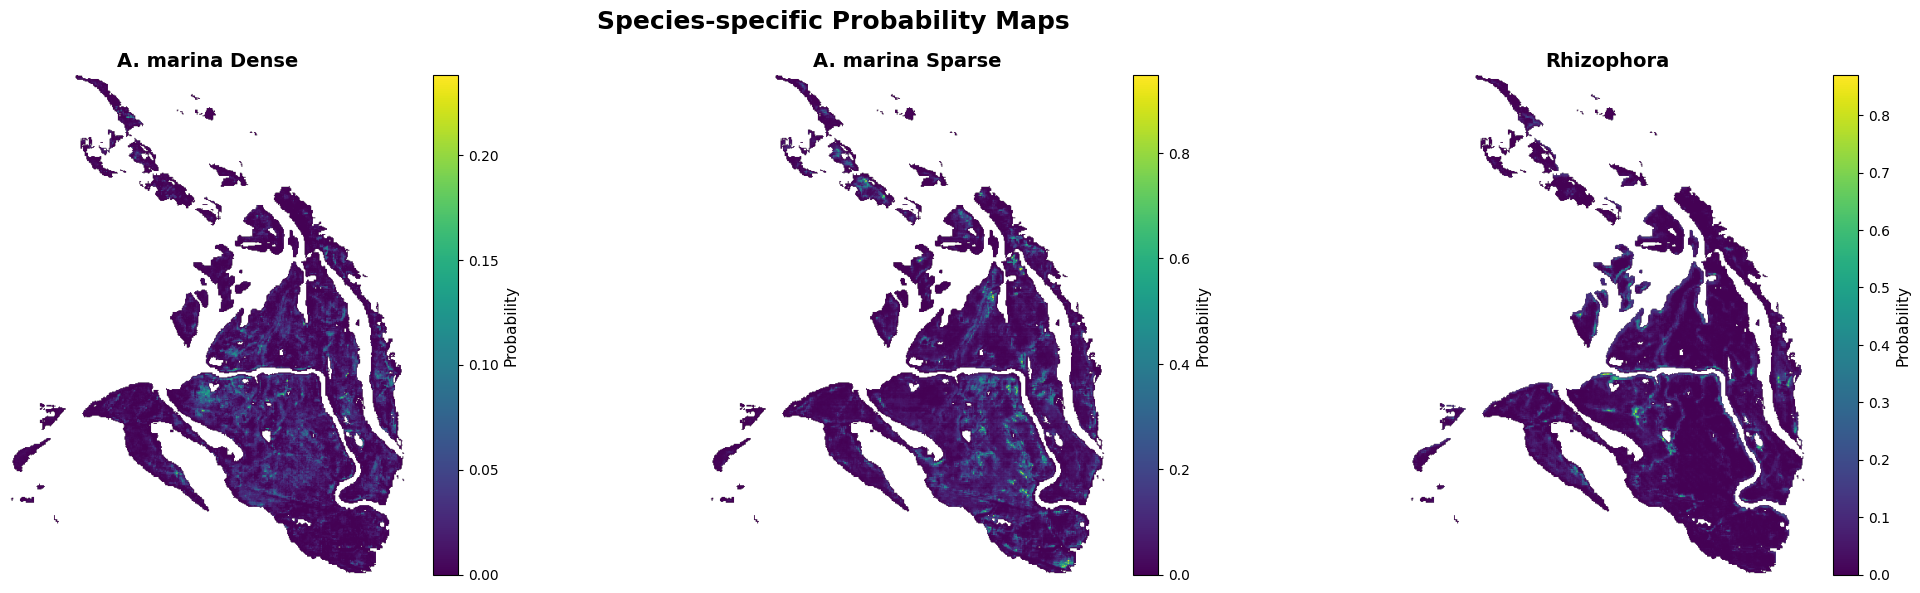

In [48]:
import rasterio
import matplotlib.pyplot as plt
import os

maps = [
    (r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Dense_Pich_Probability.tif", "A. marina Dense"),
    (r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Sparse_Pich_Probability.tif", "A. marina Sparse"),
    (r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Rhizophora_Probability.tif", "Rhizophora sp."),
]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

maps = [
    (dense_map, "A. marina Dense"),
    (sparse_map, "A. marina Sparse"),
    (rhizophora_map, "Rhizophora"),
]

for ax, (img, title) in zip(axes, maps):

    valid = img[np.isfinite(img)]

    vmin = valid.min()
    vmax = valid.max()

    im = ax.imshow(
        img,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

    cbar = plt.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label("Probability", fontsize=11)

plt.suptitle(
    "Species-specific Probability Maps",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Species_specific_probability_Maps.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [49]:
import rasterio
import pandas as pd
import seaborn as sns
from rasterio.features import geometry_mask

probability_maps = {
    "Dense": rasterio.open(
        os.path.join(MAP_FOLDER, r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Dense_Pich_Probability.tif")
    ).read(1),

    "Sparse": rasterio.open(
        os.path.join(MAP_FOLDER, r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Sparse_Pich_Probability.tif")
    ).read(1),

    "Rhizophora": rasterio.open(
        os.path.join(MAP_FOLDER, r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Rhizophora_Pich_Probability.tif")
    ).read(1),
}

In [50]:
pich_gt = gpd.read_file(PICH_GT)

pich_gt_eval = pich_gt[pich_gt["label"] != "mud"].copy()
pich_gt_eval = pich_gt_eval[pich_gt_eval["label"] != "sand"].copy()
pich_gt_eval = pich_gt_eval[pich_gt_eval["label"] != "other_vegetation"].copy()
pich_gt_eval = pich_gt_eval[pich_gt_eval["label"] != "waterbody_creek"].copy()
pich_gt_eval = pich_gt_eval[pich_gt_eval["label"] != "A_marina_moderate"].copy()
print(pich_gt_eval["label"].value_counts())

label
A_marina_sparse    545
A_marina_dense     454
Rhizophora         255
Name: count, dtype: int64


In [51]:
results = []

for _, row in pich_gt_eval.iterrows():

    mask_geom = geometry_mask(
        [row.geometry],
        transform=pich_transform,
        invert=True,
        out_shape=(rows, cols)
    )

    record = {
        "GT": row["label"]
    }

    for model_name, prob in probability_maps.items():

        values = prob[mask_geom]

        values = values[np.isfinite(values)]

        record[model_name] = np.mean(values)

    results.append(record)

In [52]:
matrix = (
    pd.DataFrame(results)
      .groupby("GT")
      .mean()
)

matrix

,Dense,Sparse,Rhizophora
GT,,,
A_marina_dense,0.013093,0.042159,0.017524
A_marina_sparse,0.010084,0.071244,0.018734
Rhizophora,0.021208,0.061592,0.123160


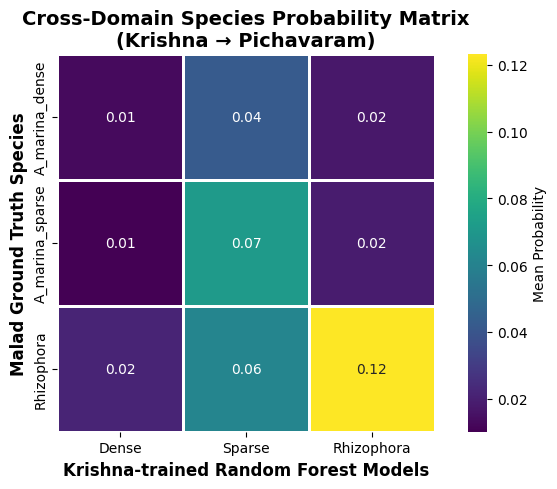

In [53]:
plt.figure(figsize=(7,5))

ax = sns.heatmap(
    matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=1,
    square=True,
    cbar_kws={
        "label":"Mean Probability"
    }
)

ax.set_xlabel(
    "Krishna-trained Random Forest Models",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Malad Ground Truth Species",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Cross-Domain Species Probability Matrix\n(Krishna → Pichavaram)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Cross_domain_probability_matrix.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [54]:
dense_map = probability_maps["Dense"]
sparse_map = probability_maps["Sparse"]
rhizophora_map = probability_maps["Rhizophora"]

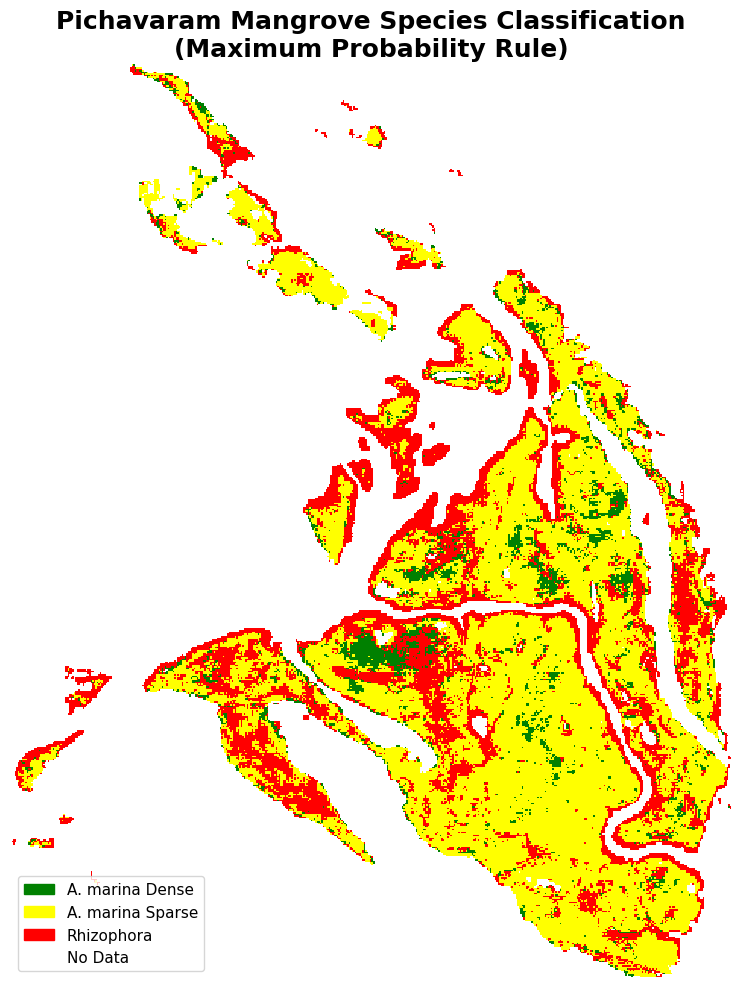

In [55]:

# Stack Mangrove Probability Maps

prob_stack = np.stack([
    dense_map,
    sparse_map,
    rhizophora_map
], axis=0)

# Class IDs
# 0 = Dense
# 1 = Sparse
# 2 = Rhizophora

species_map = np.argmax(prob_stack, axis=0).astype(np.uint8)

# Outside AOI

species_map[~valid_mask] = 255

# Plot
colors = [
    "#008000",   # Dense - Green
    "#FFFF00",   # Sparse - Yellow
    "#FF0000",   # Rhizophora - Red
    "#FFFFFF"    # No Data - White
]

cmap = ListedColormap(colors)

plot_map = species_map.copy()

# Replace NoData (255) with index 3
plot_map[plot_map == 255] = 3

plt.figure(figsize=(10,10))

plt.imshow(
    plot_map,
    cmap=cmap,
    interpolation="nearest"
)

legend = [
    Patch(color="#008000", label="A. marina Dense"),
    Patch(color="#FFFF00", label="A. marina Sparse"),
    Patch(color="#FF0000", label="Rhizophora"),
    Patch(color="#FFFFFF", label="No Data")
]

plt.legend(
    handles=legend,
    loc="lower left",
    fontsize=11,
    frameon=True
)

plt.title(
    "Pichavaram Mangrove Species Classification\n(Maximum Probability Rule)",
    fontsize=18,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Pichavaram_Final_Species_Classification.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [56]:
from rasterio.features import geometry_mask
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    cohen_kappa_score
)

# Mapping between GT labels and class IDs in species_map
label_to_id = {
    "A_marina_dense": 0,
    "A_marina_sparse": 1,
    "Rhizophora": 2
}

# Use only vegetation classes
eval_gt = pich_gt[pich_gt["label"].isin(label_to_id.keys())].copy()

y_true = []
y_pred = []

for _, row in eval_gt.iterrows():

    mask = geometry_mask(
        [row.geometry],
        out_shape=species_map.shape,
        transform=pich_transform,
        invert=True
    )

    pixels = species_map[mask]

    # Remove NoData (255)
    pixels = pixels[pixels != 255]

    if len(pixels) == 0:
        continue

    # Majority vote
    predicted = np.bincount(pixels.astype(int)).argmax()

    y_true.append(label_to_id[row["label"]])
    y_pred.append(predicted)

print("Number of evaluated polygons:", len(y_true))

Number of evaluated polygons: 1249


In [57]:
oa = accuracy_score(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)

print(f"Overall Accuracy : {oa:.4f}")
print(f"Kappa            : {kappa:.4f}")

Overall Accuracy : 0.4892
Kappa            : 0.1957


In [58]:
print(classification_report(
    y_true,
    y_pred,
    target_names=[
        "Dense",
        "Sparse",
        "Rhizophora"
    ],
    digits=3
))

              precision    recall  f1-score   support

       Dense      0.377     0.051     0.089       454
      Sparse      0.478     0.727     0.576       545
  Rhizophora      0.535     0.768     0.631       250

    accuracy                          0.489      1249
   macro avg      0.463     0.515     0.432      1249
weighted avg      0.453     0.489     0.410      1249



In [59]:
cm = confusion_matrix(y_true, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Dense",
        "Sparse",
        "Rhizophora"
    ],
    columns=[
        "Dense",
        "Sparse",
        "Rhizophora"
    ]
)

cm_df

,Dense,Sparse,Rhizophora
Dense,23,379,52
Sparse,34,396,115
Rhizophora,4,54,192


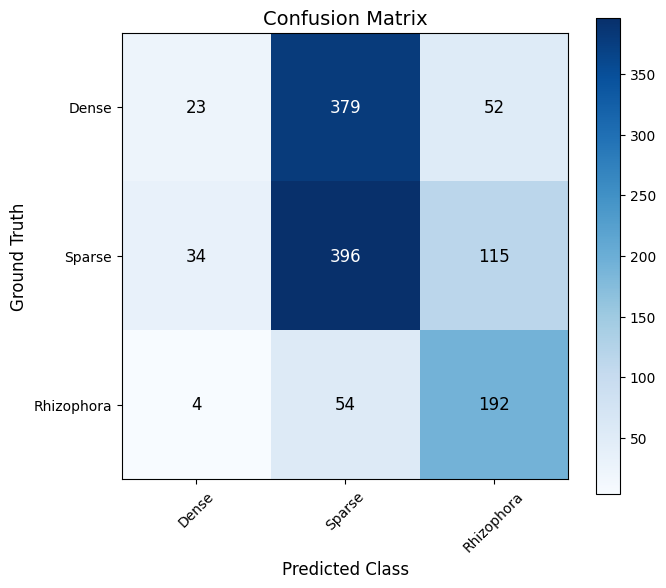

In [60]:
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "Dense",
    "Sparse",
    "Rhizophora"
]

plt.figure(figsize=(7,6))

plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title("Confusion Matrix", fontsize=14)
plt.colorbar()

tick_marks = np.arange(len(class_names))

plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

# Write values inside each cell
thresh = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            format(cm[i, j], 'd'),
            ha="center",
            va="center",
            color="white" if cm[i, j] > thresh else "black",
            fontsize=12
        )

plt.ylabel("Ground Truth", fontsize=12)
plt.xlabel("Predicted Class", fontsize=12)

plt.tight_layout()

plt.show()